In [1]:
import os
import zipfile
import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

print("Libraries imported successfully!")
print("NumPy version:",np.__version__)

Libraries imported successfully!
NumPy version: 2.1.3


In [2]:
# Download the AT&T/ORL Database of Faces
DATA_URL=("https://www.cl.cam.ac.uk/research/dtg/attarchive/pub/data/att_faces.zip")
zip_path="/content/att_faces.zip"
extract_path="/content/orl_faces"

if not os.path.exists(zip_path):
    urllib.request.urlretrieve(DATA_URL,zip_path)
os.makedirs(extract_path,exist_ok=True)

if not os.path.exists(os.path.join(extract_path,"s1")):
    with zipfile.ZipFile(zip_path,"r") as zip_ref:
        zip_ref.extractall(extract_path)

# Locate the subject folders
subject_dirs=sorted([p for p in Path(extract_path).rglob("*") if p.is_dir() and p.name.startswith("s") and p.name[1:].isdigit()],key=lambda p:int(p.name[1:]))

print("Dataset downloaded and extracted.")
print("Number of subjects:",len(subject_dirs))
print("Dataset location:",extract_path)

Dataset downloaded and extracted.
Number of subjects: 40
Dataset location: /content/orl_faces


In [3]:
images=[]
labels=[]
image_paths=[]

for subject_dir in subject_dirs:
    subject_id=int(subject_dir.name[1:])
    files=sorted(subject_dir.glob("*.pgm"),key=lambda p:int(p.stem))

    for file_path in files:
        with Image.open(file_path) as img:
            gray_image=np.array(img.convert("L"),dtype=np.uint8)

        images.append(gray_image)
        labels.append(subject_id)
        image_paths.append(str(file_path))

images=np.array(images)
labels=np.array(labels)
image_paths=np.array(image_paths)

print("Image array shape:",images.shape)
print("Label array shape:",labels.shape)
print("Unique subjects:",len(np.unique(labels)))
print("Pixel intensity range:",images.min(),"to",images.max())
print("Image dimensions:",images[0].shape)

Image array shape: (400, 112, 92)
Label array shape: (400,)
Unique subjects: 40
Pixel intensity range: 0 to 251
Image dimensions: (112, 92)


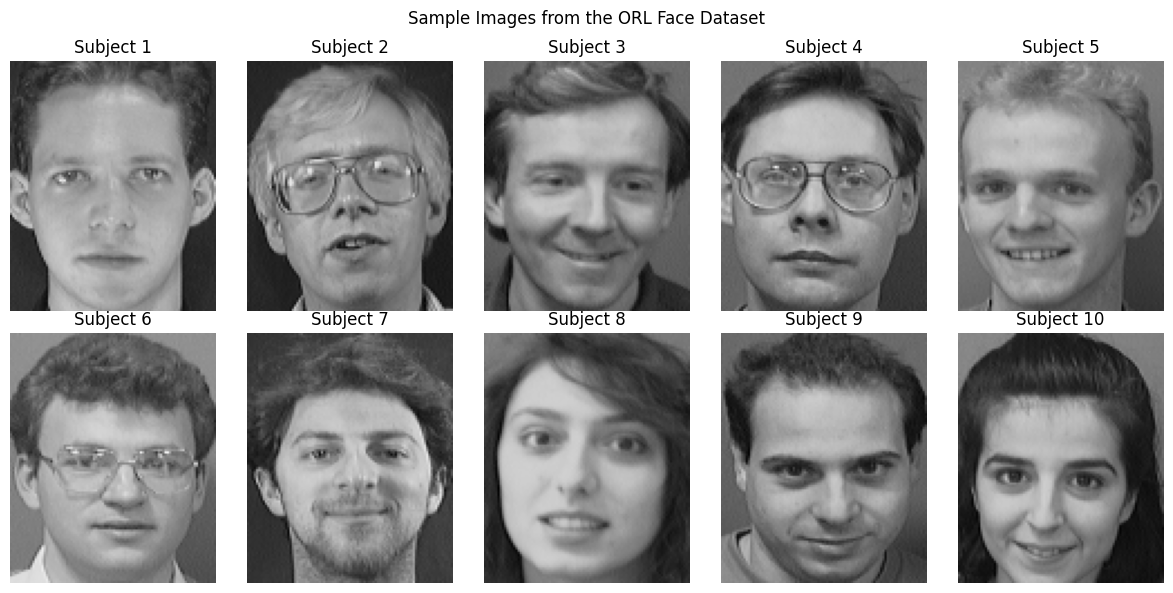

In [4]:
# Display sample images from different subjects
fig,axes=plt.subplots(2,5,figsize=(12,6))
for i,ax in enumerate(axes.flat):
    ax.imshow(images[i*10],cmap="gray",vmin=0,vmax=255)
    ax.set_title(f"Subject {labels[i*10]}")
    ax.axis("off")

plt.suptitle("Sample Images from the ORL Face Dataset")
plt.tight_layout()
plt.show()

In [5]:
# Convert each 2D image into a 1D feature vector
X=images.reshape(images.shape[0],-1)

# Convert to float for linear algebra operations
X=X.astype(np.float64)

print("Complete image matrix shape:",X.shape)
print("Number of images:",X.shape[0])
print("Features per image:",X.shape[1])
print("Memory used by X:",round(X.nbytes/(1024**2),2),"MB")

Complete image matrix shape: (400, 10304)
Number of images: 400
Features per image: 10304
Memory used by X: 31.45 MB


In [6]:
# Split images separately within each subject
rng=np.random.default_rng(42)
train_indices=[]
test_indices=[]

for subject_id in np.unique(labels):
    subject_indices=np.where(labels==subject_id)[0]
    subject_indices=rng.permutation(subject_indices)

    train_indices.extend(subject_indices[:7])
    test_indices.extend(subject_indices[7:])

train_indices=np.array(train_indices)
test_indices=np.array(test_indices)

# Shuffle the combined training and test indices
train_indices=rng.permutation(train_indices)
test_indices=rng.permutation(test_indices)

X_train=X[train_indices]
X_test=X[test_indices]
y_train=labels[train_indices]
y_test=labels[test_indices]

print("Training data:",X_train.shape)
print("Testing data:",X_test.shape)
print("Training subjects:",len(np.unique(y_train)))
print("Testing subjects:",len(np.unique(y_test)))

assert set(y_train)==set(y_test)
assert len(set(train_indices) & set(test_indices))==0
assert len(train_indices)+len(test_indices)==len(X)

Training data: (280, 10304)
Testing data: (120, 10304)
Training subjects: 40
Testing subjects: 40


Mean face shape: (10304,)
Centered training shape: (280, 10304)
Centered test shape: (120, 10304)


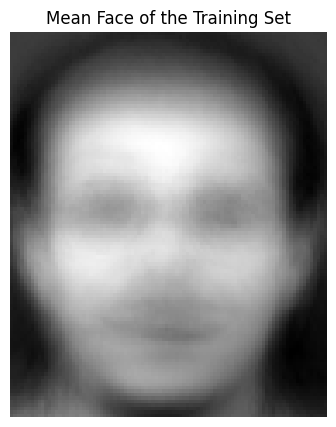

In [7]:
# Calculate the mean face using training data only
mean_face=np.mean(X_train,axis=0)
X_train_centered=X_train-mean_face
X_test_centered=X_test-mean_face

print("Mean face shape:",mean_face.shape)
print("Centered training shape:",X_train_centered.shape)
print("Centered test shape:",X_test_centered.shape)

# Visualize the mean face
plt.figure(figsize=(5,5))
plt.imshow(mean_face.reshape(images.shape[1:]),cmap="gray")
plt.title("Mean Face of the Training Set")
plt.axis("off")
plt.show()

In [8]:
# PCA using sample-space covariance and eigendecomposition
n_train,n_features=X_train_centered.shape
covariance_small=(X_train_centered @ X_train_centered.T)/(n_train-1)
eigenvalues_cov,eigenvectors_cov=np.linalg.eigh(covariance_small)

# Sort eigenvalues from largest to smallest
order=np.argsort(eigenvalues_cov)[::-1]
eigenvalues_cov=eigenvalues_cov[order]
eigenvectors_cov=eigenvectors_cov[:,order]

# Remove tiny negative values caused by floating-point error
eigenvalues_cov=np.maximum(eigenvalues_cov,0)

# Keep only meaningful principal directions
tol=eigenvalues_cov[0]*1e-12
valid=eigenvalues_cov > tol
eigenvalues_cov=eigenvalues_cov[valid]
eigenvectors_cov=eigenvectors_cov[:,valid]

# Map sample-space eigenvectors into pixel space
eigenfaces_cov=(X_train_centered.T @ eigenvectors_cov)/np.sqrt((n_train-1)*eigenvalues_cov)

print("Covariance matrix shape:",covariance_small.shape)
print("Eigenfaces matrix shape:",eigenfaces_cov.shape)
print("Number of nonzero principal directions:",len(eigenvalues_cov))

Covariance matrix shape: (280, 280)
Eigenfaces matrix shape: (10304, 279)
Number of nonzero principal directions: 279


In [9]:
# PCA using NumPy SVD
U_svd,singular_values,Vt_svd=np.linalg.svd(X_train_centered,full_matrices=False)
eigenvalues_svd=(singular_values**2)/(n_train-1)
eigenfaces_svd=Vt_svd.T

print("U shape:",U_svd.shape)
print("Singular values shape:",singular_values.shape)
print("V-transpose shape:",Vt_svd.shape)
print("SVD eigenfaces shape:",eigenfaces_svd.shape)

U shape: (280, 280)
Singular values shape: (280,)
V-transpose shape: (280, 10304)
SVD eigenfaces shape: (10304, 280)


In [10]:
# Compare eigenvalues from the two methods
num_compare=min(len(eigenvalues_cov),len(eigenvalues_svd))
relative_eigenvalue_error=(np.linalg.norm(eigenvalues_cov[:num_compare]- eigenvalues_svd[:num_compare])/ (np.linalg.norm(eigenvalues_svd[:num_compare])+1e-12))
print("Relative eigenvalue difference:",f"{relative_eigenvalue_error:.3e}")

# Compare the subspaces using absolute cosine similarity
# Absolute value handles arbitrary eigenvector signs.
num_directions=min(10,num_compare)
cosine_similarity=np.abs(np.sum(eigenfaces_cov[:,:num_directions]* eigenfaces_svd[:,:num_directions],axis=0))

print("Cosine similarities for first principal directions:")
print(np.round(cosine_similarity,6))

Relative eigenvalue difference: 1.969e-15
Cosine similarities for first principal directions:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Components needed for 90% variance: 92
Variance retained: 90.04%


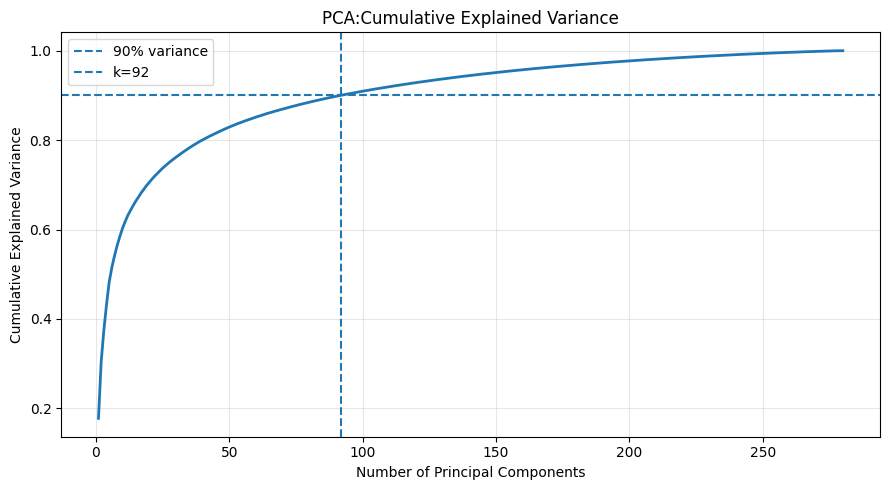

In [11]:
# Calculate explained variance using SVD eigenvalues
explained_variance_ratio=(eigenvalues_svd/np.sum(eigenvalues_svd))
cumulative_variance=np.cumsum(explained_variance_ratio)

# Minimum number of components needed for at least 90% variance
k90=np.searchsorted(cumulative_variance,0.90)+1

print("Components needed for 90% variance:",k90)
print("Variance retained:",f"{cumulative_variance[k90-1]*100:.2f}%")

plt.figure(figsize=(9,5))
plt.plot(np.arange(1,len(cumulative_variance)+1),cumulative_variance,linewidth=2)
plt.axhline(0.90,linestyle="--",label="90% variance")
plt.axvline(k90,linestyle="--",label=f"k={k90}")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA:Cumulative Explained Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("explained_variance.png",dpi=200,bbox_inches="tight")
plt.show()

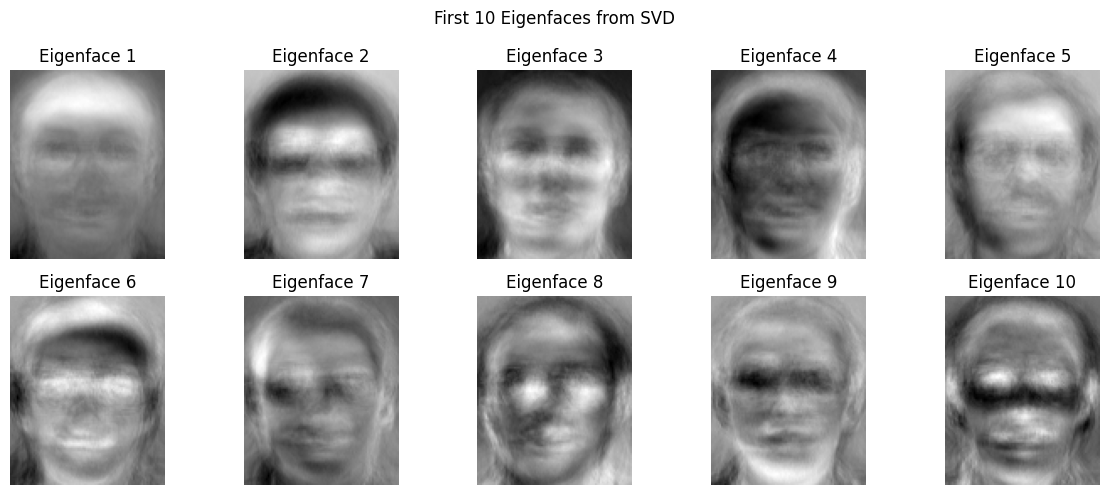

In [12]:
# Visualize the first 10 eigenfaces
num_eigenfaces=min(10,eigenfaces_svd.shape[1])
fig,axes=plt.subplots(2,5,figsize=(12,5))

for i,ax in enumerate(axes.flat[:num_eigenfaces]):
    eigenface=eigenfaces_svd[:,i].reshape(images.shape[1:])
    ax.imshow(eigenface,cmap="gray")
    ax.set_title(f"Eigenface {i+1}")
    ax.axis("off")

plt.suptitle("First 10 Eigenfaces from SVD")
plt.tight_layout()
plt.savefig("eigenfaces.png",dpi=200,bbox_inches="tight")
plt.show()

In [13]:
# Select principal directions
components=eigenfaces_svd[:,:k90]

# Project training and test data into the same PCA space
X_train_pca=X_train_centered @ components
X_test_pca=X_test_centered @ components

print("Selected components:",k90)
print("Reduced training matrix:",X_train_pca.shape)
print("Reduced test matrix:",X_test_pca.shape)

Selected components: 92
Reduced training matrix: (280, 92)
Reduced test matrix: (120, 92)


Mean squared reconstruction error: 288.3629995170502


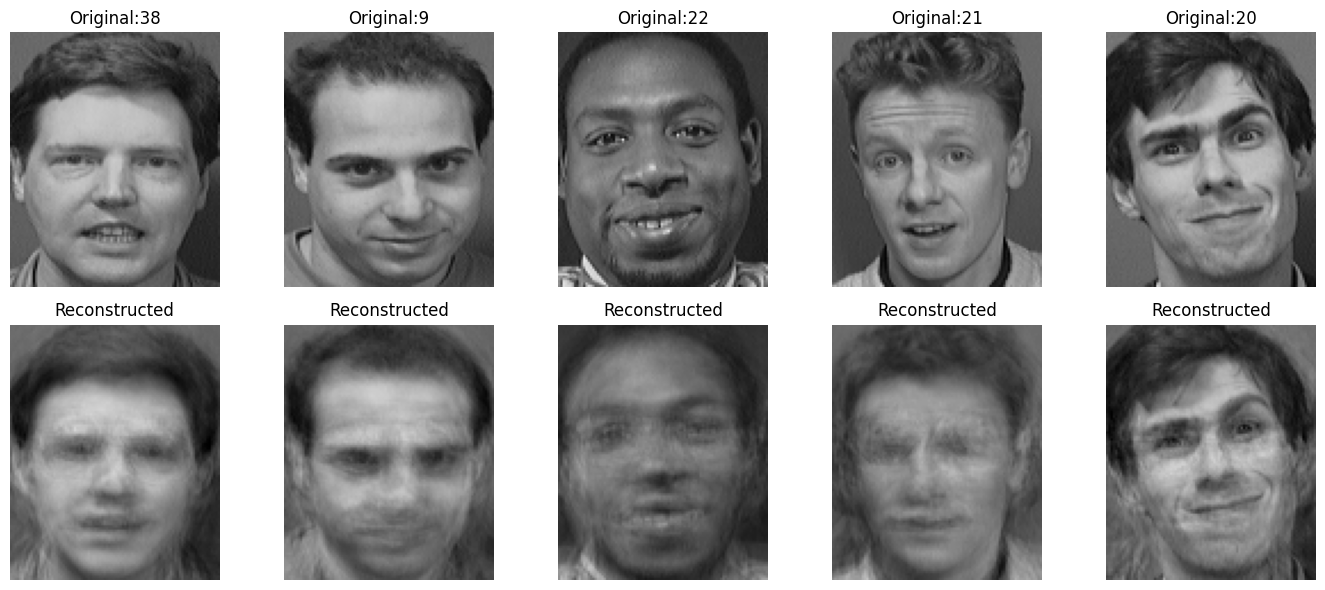

In [14]:
# Reconstruct several test images
num_examples=5
original_faces=X_test[:num_examples]
reconstructed_faces=(X_test_pca[:num_examples] @ components.T)+mean_face
reconstruction_mse=np.mean((original_faces-reconstructed_faces)**2)
print("Mean squared reconstruction error:",reconstruction_mse)
fig,axes=plt.subplots(2,num_examples,figsize=(14,6))

for i in range(num_examples):
    axes[0,i].imshow(original_faces[i].reshape(images.shape[1:]),cmap="gray",vmin=0,vmax=255)
    axes[0,i].set_title(f"Original:{y_test[i]}")
    axes[1,i].imshow(np.clip(reconstructed_faces[i].reshape(images.shape[1:]),0,255),cmap="gray",vmin=0,vmax=255)
    axes[1,i].set_title("Reconstructed")
    axes[0,i].axis("off")
    axes[1,i].axis("off")

plt.tight_layout()
plt.savefig("reconstruction_examples.png",dpi=200,bbox_inches="tight")
plt.show()

In [15]:
# Compare raw pixel storage and PCA coefficient storage
bytes_per_value=X.dtype.itemsize
original_bytes=X.shape[1]*bytes_per_value
pca_bytes=k90*bytes_per_value

print("Original features per image:",X.shape[1])
print("PCA features per image:",k90)
print("Original bytes per image:",original_bytes)
print("PCA coefficient bytes per image:",pca_bytes)
print("Coefficient-only reduction:",f"{100*(1-pca_bytes/original_bytes):.2f}%")

# Approximate total storage for the training representation,
# including the mean face and selected PCA basis.
original_training_bytes=X_train.size*bytes_per_value
pca_training_bytes=(X_train_pca.size+mean_face.size+components.size)*bytes_per_value

print("Original training matrix (MB):",round(original_training_bytes/1e6,3))
print("PCA representation+basis (MB):",round(pca_training_bytes/1e6,3))

Original features per image: 10304
PCA features per image: 92
Original bytes per image: 82432
PCA coefficient bytes per image: 736
Coefficient-only reduction: 99.11%
Original training matrix (MB): 23.081
PCA representation+basis (MB): 7.872


In [16]:
# Nearest-neighbor recognition without scikit-learn
def nearest_neighbor_predict(X_reference,y_reference,X_query):
    predictions=[]

    for query in X_query:
        distances=np.linalg.norm(X_reference-query,axis=1)
        nearest_index=np.argmin(distances)
        predictions.append(y_reference[nearest_index])
    return np.array(predictions)

# Raw-pixel matching
y_pred_raw=nearest_neighbor_predict(X_train,y_train,X_test)

# PCA-space matching
y_pred_pca=nearest_neighbor_predict(X_train_pca,y_train,X_test_pca)
raw_accuracy=np.mean(y_pred_raw==y_test)
pca_accuracy=np.mean(y_pred_pca==y_test)

print(f"Raw-pixel accuracy:{raw_accuracy:.4f}")
print(f"PCA nearest-neighbor accuracy:{pca_accuracy:.4f}")

Raw-pixel accuracy:0.9750
PCA nearest-neighbor accuracy:0.9750


In [17]:
# Nearest-neighbor recognition without scikit-learn
def nearest_neighbor_predict(X_reference,y_reference,X_query):
    predictions=[]

    for query in X_query:
        distances=np.linalg.norm(X_reference-query,axis=1)
        nearest_index=np.argmin(distances)
        predictions.append(y_reference[nearest_index])
    return np.array(predictions)

# Raw-pixel matching
y_pred_raw=nearest_neighbor_predict(X_train,y_train,X_test)

# PCA-space matching
y_pred_pca=nearest_neighbor_predict(X_train_pca,y_train,X_test_pca)
raw_accuracy=np.mean(y_pred_raw==y_test)
pca_accuracy=np.mean(y_pred_pca==y_test)

print(f"Raw-pixel accuracy:{raw_accuracy:.4f}")
print(f"PCA nearest-neighbor accuracy:{pca_accuracy:.4f}")

Raw-pixel accuracy:0.9750
PCA nearest-neighbor accuracy:0.9750


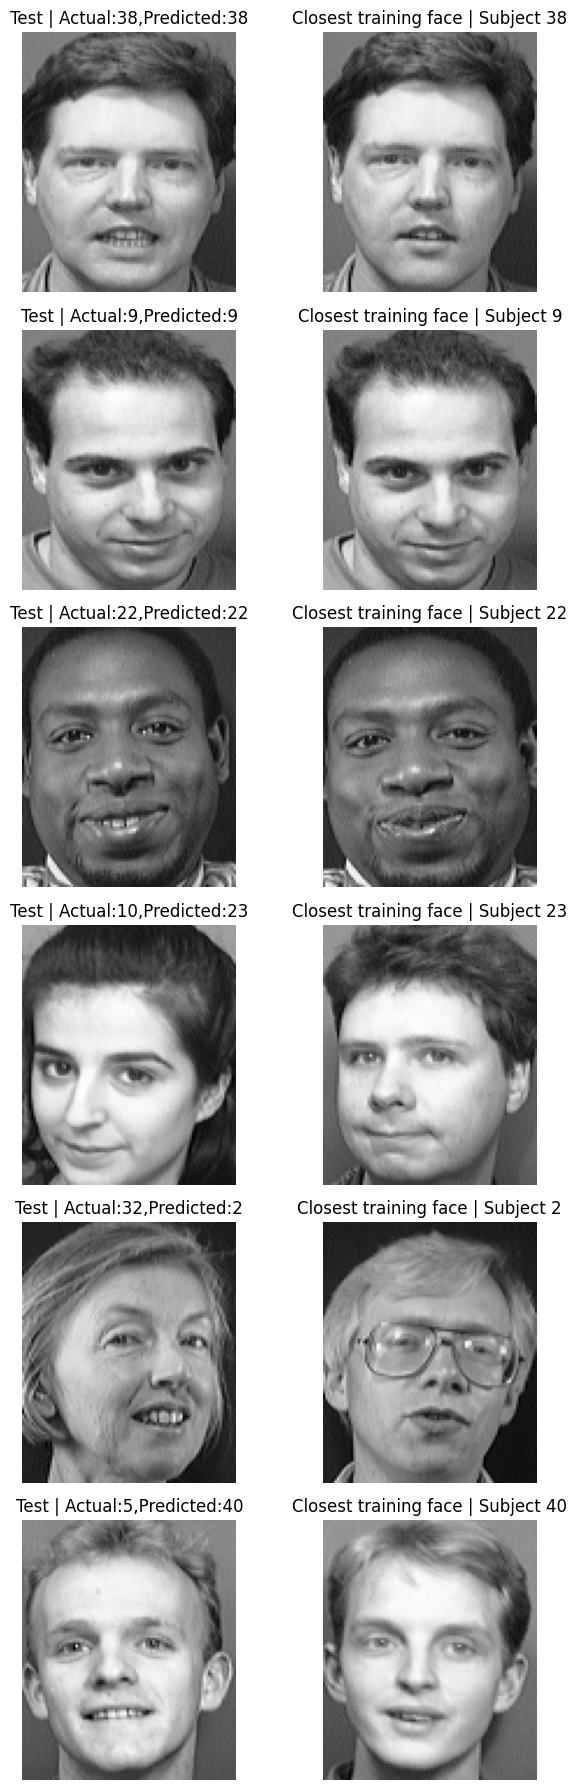

In [18]:
# Display several correct and incorrect PCA matches
correct_indices=np.where(y_pred_pca==y_test)[0]
incorrect_indices=np.where(y_pred_pca != y_test)[0]
selected_indices=list(correct_indices[:3])+list(incorrect_indices[:3])

if not selected_indices:
    print("No test predictions available.")
else:
    fig,axes=plt.subplots(len(selected_indices),2,figsize=(7,3*len(selected_indices)))

    if len(selected_indices)==1:
        axes=np.array([axes])

    for row,idx in enumerate(selected_indices):
        distances=np.linalg.norm(X_train_pca-X_test_pca[idx],axis=1)
        match_idx=np.argmin(distances)
        axes[row,0].imshow(X_test[idx].reshape(images.shape[1:]),cmap="gray")
        axes[row,0].set_title(f"Test | Actual:{y_test[idx]},Predicted:{y_pred_pca[idx]}")
        axes[row,1].imshow(X_train[match_idx].reshape(images.shape[1:]),cmap="gray")
        axes[row,1].set_title(f"Closest training face | Subject {y_train[match_idx]}")

        axes[row,0].axis("off")
        axes[row,1].axis("off")

    plt.tight_layout()
    plt.savefig("recognition_examples.png",dpi=200,bbox_inches="tight")
    plt.show()

In [19]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,classification_report

classifiers={"KNN (k=1)":KNeighborsClassifier(n_neighbors=1),"Logistic Regression":LogisticRegression( max_iter=3000,random_state=42),
"SVM (RBF)":SVC(kernel="rbf",C=10,gamma="scale")}

results=[{"Method":"Raw-pixel nearest neighbor","Components":X_train.shape[1],"Accuracy":accuracy_score(y_test,y_pred_raw)},
{"Method":"PCA nearest neighbor","Components":k90,"Accuracy":accuracy_score(y_test,y_pred_pca)}]

trained_models={}

for name,model in classifiers.items():
    model.fit(X_train_pca,y_train)
    predictions=model.predict(X_test_pca)

    trained_models[name]=model
    results.append({"Method":name,"Components":k90,"Accuracy":accuracy_score(y_test,predictions)})

    print(f"\n{name}")
    print(classification_report(y_test,predictions,zero_division=0))

results_df=pd.DataFrame(results)
results_df["Accuracy (%)"]=(results_df["Accuracy"]*100).round(2)
display(results_df)
results_df.to_csv("recognition_results.csv",index=False)


KNN (k=1)
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         3
           2       0.75      1.00      0.86         3
           3       1.00      1.00      1.00         3
           4       1.00      1.00      1.00         3
           5       1.00      0.67      0.80         3
           6       1.00      1.00      1.00         3
           7       1.00      1.00      1.00         3
           8       1.00      1.00      1.00         3
           9       1.00      1.00      1.00         3
          10       1.00      0.67      0.80         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         3
          13       1.00      1.00      1.00         3
          14       1.00      1.00      1.00         3
          15       1.00      1.00      1.00         3
          16       1.00      1.00      1.00         3
          17       1.00      1.00      1.00         3
          18    

,Method,Components,Accuracy,Accuracy (%)
0,Raw-pixel nearest neighbor,10304,0.975000,97.50
1,PCA nearest neighbor,92,0.975000,97.50
2,KNN (k=1),92,0.975000,97.50
3,Logistic Regression,92,0.991667,99.17
4,SVM (RBF),92,0.983333,98.33


In [20]:
# Experiment with multiple component counts
candidate_counts=sorted(set([min(20,k90),min(40,k90),k90,min(150,X_train_pca.shape[1])]))

# Remove duplicates and invalid values
candidate_counts=[k for k in candidate_counts if k > 0]
component_results=[]

for k in candidate_counts:
    basis_k=eigenfaces_svd[:,:k]
    train_k=X_train_centered @ basis_k
    test_k=X_test_centered @ basis_k
    nn_pred=nearest_neighbor_predict(train_k,y_train,test_k)

    svm=SVC(kernel="rbf",C=10,gamma="scale")
    svm.fit(train_k,y_train)
    svm_pred=svm.predict(test_k)

    component_results.append({"Components":k,"Variance Retained (%)":round( cumulative_variance[k-1]*100,2),
        "NN Accuracy (%)":round(accuracy_score(y_test,nn_pred)*100,2),
        "SVM Accuracy (%)":round(accuracy_score(y_test,svm_pred)*100,2)})

component_results_df=pd.DataFrame(component_results)
display(component_results_df)
component_results_df.to_csv("component_experiments.csv",index=False)

,Components,Variance Retained (%),NN Accuracy (%),SVM Accuracy (%)
0,20,70.55,95.0,95.83
1,40,80.04,97.5,97.50
2,92,90.04,97.5,98.33


In [21]:
import shutil
import os

output_dir="/content/ds605_lab7_results"
os.makedirs(output_dir,exist_ok=True)

deliverables=["explained_variance.png","eigenfaces.png","reconstruction_examples.png","recognition_examples.png","recognition_results.csv","component_experiments.csv"]

for filename in deliverables:
    source=f"/content/file1"
    if os.path.exists(source):
        shutil.copy2(source,output_dir)

print("Saved deliverables:")
for filename in sorted(os.listdir(output_dir)):
    print("-",filename)

shutil.make_archive("/content/ds605_lab7_results","zip",output_dir)
print("Created /content/ds605_lab7_results.zip")

Saved deliverables:
- component_experiments.csv
- recognition_results.csv
Created /content/ds605_lab7_results.zip


In [22]:
from google.colab import files
files.download("/content/ds605_lab7_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
print("results_df exists:", "results_df" in globals())
print("component_results_df exists:", "component_results_df" in globals())

if "results_df" in globals():
    display(results_df)

if "component_results_df" in globals():
    display(component_results_df)

results_df exists: True
component_results_df exists: True


,Method,Components,Accuracy,Accuracy (%)
0,Raw-pixel nearest neighbor,10304,0.975000,97.50
1,PCA nearest neighbor,92,0.975000,97.50
2,KNN (k=1),92,0.975000,97.50
3,Logistic Regression,92,0.991667,99.17
4,SVM (RBF),92,0.983333,98.33


,Components,Variance Retained (%),NN Accuracy (%),SVM Accuracy (%)
0,20,70.55,95.0,95.83
1,40,80.04,97.5,97.50
2,92,90.04,97.5,98.33


In [24]:
import os

output_dir = "/content/ds605_lab7_results"
os.makedirs(output_dir, exist_ok=True)

results_df.to_csv(
    f"{output_dir}/recognition_results.csv",
    index=False
)

component_results_df.to_csv(
    f"{output_dir}/component_experiments.csv",
    index=False
)

print("Recognition results:")
display(pd.read_csv(f"{output_dir}/recognition_results.csv"))

print("Component experiments:")
display(pd.read_csv(f"{output_dir}/component_experiments.csv"))

Recognition results:


,Method,Components,Accuracy,Accuracy (%)
0,Raw-pixel nearest neighbor,10304,0.975000,97.50
1,PCA nearest neighbor,92,0.975000,97.50
2,KNN (k=1),92,0.975000,97.50
3,Logistic Regression,92,0.991667,99.17
4,SVM (RBF),92,0.983333,98.33


Component experiments:


,Components,Variance Retained (%),NN Accuracy (%),SVM Accuracy (%)
0,20,70.55,95.0,95.83
1,40,80.04,97.5,97.50
2,92,90.04,97.5,98.33
